# Week 2 · Exploratory Data Analysis (EDA)
**Kagnus Data Analytics Internship · Food Delivery Operations**

**Goal:** use the cleaned Week 1 dataset to establish a delivery-duration baseline, compare operational factors (traffic, weather, distance, vehicle type and others), and write number-supported observations.

**How this notebook is organised**
1. Setup and loading the cleaned data
2. Data checks and field availability
3. Delivery-duration baseline
4. Traffic, weather and vehicle comparisons
5. Distance analysis, correlation and the initial scatter plot
6. Additional fields (multiple deliveries, ratings, partner age)
7. Key observations (each with question, metric, result, comparison and group size)
8. Limitations

**How to read the results:** every number in the written text is calculated by code from the data. Each observation separates **what the data shows** from **interpretation**. An association between two things does not prove that one causes the other.

## 1. Setup

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Markdown

pd.set_option("display.max_columns", None)
sns.set_theme(style="whitegrid")

def md_table(frame):
    # Turn a DataFrame into a Markdown table so results render cleanly on GitHub
    cols = [str(c) for c in frame.columns]
    lines = ["| " + " | ".join(cols) + " |", "| " + " | ".join(["---"] * len(cols)) + " |"]
    for _, row in frame.iterrows():
        lines.append("| " + " | ".join(str(v) for v in row.values) + " |")
    return "\n".join(lines)

def show_md(*lines):
    display(Markdown("\n".join(lines)))

### 1.1 Load the cleaned dataset

**What:** load `cleaned_food_delivery.csv`, the output of Week 1. **Why:** Week 2 must continue with the same cleaned data, not restart with different data.

In [2]:
CWD = os.getcwd()
PROJECT_ROOT = os.path.dirname(CWD) if os.path.basename(CWD).lower() == "notebooks" else CWD

CLEAN_NAME = "cleaned_food_delivery.csv"
candidates = [os.path.join(PROJECT_ROOT, "data", "processed", CLEAN_NAME), os.path.join(CWD, CLEAN_NAME)]
CLEAN_PATH = next((p for p in candidates if os.path.exists(p)), None)
if CLEAN_PATH is None:
    raise FileNotFoundError("Cleaned CSV not found. Run the Week 1 notebook first. Looked in:\n  " + "\n  ".join(candidates))

df = pd.read_csv(CLEAN_PATH)
if "Order_Date" in df.columns:
    df["Order_Date"] = pd.to_datetime(df["Order_Date"], errors="coerce")

print("Loaded:", CLEAN_PATH)
print("Shape (rows, columns):", df.shape)
df.head()

Loaded: C:\Users\HP\Documents\food-delivery-data-analysis\data\processed\cleaned_food_delivery.csv
Shape (rows, columns): (45584, 21)


,ID,Delivery_person_ID,Delivery_person_Age,Delivery_person_Ratings,Restaurant_latitude,Restaurant_longitude,Delivery_location_latitude,Delivery_location_longitude,Order_Date,Time_Ordered,Time_Order_picked,Weather_conditions,Road_traffic_density,Vehicle_condition,Type_of_order,Type_of_vehicle,multiple_deliveries,Festival,City,Time_taken_min,has_valid_coordinates
0,0xcdcd,DEHRES17DEL01,36.0,4.2,30.327968,78.046106,30.397968,78.116106,2022-02-12,21:55,22:10,Fog,Jam,2,Snack,motorcycle,3.0,No,Metropolitan,46,True
1,0xd987,KOCRES16DEL01,21.0,4.7,10.003064,76.307589,10.043064,76.347589,2022-02-13,14:55,15:05,Stormy,High,1,Meal,motorcycle,1.0,No,Metropolitan,23,True
2,0x2784,PUNERES13DEL03,23.0,4.7,18.562450,73.916619,18.652450,74.006619,2022-03-04,17:30,17:40,Sandstorms,Medium,1,Drinks,scooter,1.0,No,Metropolitan,21,True
3,0xc8b6,LUDHRES15DEL02,34.0,4.3,30.899584,75.809346,30.919584,75.829346,2022-02-13,09:20,09:30,Sandstorms,Low,0,Buffet,motorcycle,0.0,No,Metropolitan,20,True
4,0xdb64,KNPRES14DEL02,24.0,4.7,26.463504,80.372929,26.593504,80.502929,2022-02-14,19:50,20:05,Fog,Jam,1,Snack,scooter,1.0,No,Metropolitan,41,True


## 2. Data Checks and Field Availability

**What:** confirm which fields exist, identify the delivery-duration column, and check it for missing or invalid values.
**Why:** the brief requires using only fields that are really present and calculating statistics only on valid records.

In [3]:
TARGET = "Time_taken_min"        # delivery duration in minutes (renamed from 'Time_taken (min)' in Week 1)
assert TARGET in df.columns, f"Duration column '{TARGET}' not found. Columns: {list(df.columns)}"

duration = df[TARGET]
n_total = len(df)
n_missing = int(duration.isna().sum())
n_nonpositive = int((duration <= 0).sum())

# Valid records: duration is present and positive
df = df[duration.notna() & (duration > 0)].copy()
n_valid = len(df)

print(f"Rows in cleaned file          : {n_total:,}")
print(f"Missing duration              : {n_missing:,}")
print(f"Zero or negative duration     : {n_nonpositive:,}")
print(f"Valid rows used in the analysis: {n_valid:,}")

Rows in cleaned file          : 45,584
Missing duration              : 0
Zero or negative duration     : 0
Valid rows used in the analysis: 45,584


In [4]:
# Which analysis fields are available in this dataset?
field_map = {
    "Traffic": "Road_traffic_density",
    "Weather": "Weather_conditions",
    "Vehicle type": "Type_of_vehicle",
    "Restaurant / destination coordinates": "Restaurant_latitude",
    "Multiple deliveries": "multiple_deliveries",
    "Ratings": "Delivery_person_Ratings",
    "Partner age": "Delivery_person_Age",
}
availability = pd.DataFrame({
    "Analysis": list(field_map.keys()),
    "Column": list(field_map.values()),
    "Available": ["Yes" if c in df.columns else "No" for c in field_map.values()],
})
availability.loc[len(availability)] = ["Partner experience", "(none)", "No: no direct experience field exists (age is not a measure of experience)"]
show_md("**Field availability**", "", md_table(availability))

HAS = {name: col in df.columns for name, col in field_map.items()}

**Field availability**

| Analysis | Column | Available |
| --- | --- | --- |
| Traffic | Road_traffic_density | Yes |
| Weather | Weather_conditions | Yes |
| Vehicle type | Type_of_vehicle | Yes |
| Restaurant / destination coordinates | Restaurant_latitude | Yes |
| Multiple deliveries | multiple_deliveries | Yes |
| Ratings | Delivery_person_Ratings | Yes |
| Partner age | Delivery_person_Age | Yes |
| Partner experience | (none) | No: no direct experience field exists (age is not a measure of experience) |

### 2.1 Derive delivery distance

**What:** calculate the straight-line (great-circle) distance in km between the restaurant and the delivery location, using only rows flagged as having valid coordinates in Week 1.
**Why:** the dataset has no distance column, but the brief asks for a distance analysis. The distance is stored in memory only and is **not** written back into the Week 1 cleaned file.
**Limitation to remember:** straight-line distance is shorter than the real road distance.

In [5]:
def haversine_km(lat1, lon1, lat2, lon2):
    r = 6371.0
    p1, p2 = np.radians(lat1), np.radians(lat2)
    a = np.sin((p2 - p1) / 2) ** 2 + np.cos(p1) * np.cos(p2) * np.sin(np.radians(lon2 - lon1) / 2) ** 2
    return 2 * r * np.arcsin(np.sqrt(a))

coord_cols = ["Restaurant_latitude", "Restaurant_longitude", "Delivery_location_latitude", "Delivery_location_longitude"]
HAS_DISTANCE = all(c in df.columns for c in coord_cols)

if HAS_DISTANCE:
    if "has_valid_coordinates" in df.columns:
        valid_coords = df["has_valid_coordinates"].astype(bool)
    else:
        valid_coords = (df["Restaurant_latitude"].between(6, 38) & df["Restaurant_longitude"].between(68, 98)
                        & df["Delivery_location_latitude"].between(6, 38) & df["Delivery_location_longitude"].between(68, 98))
    df["distance_km"] = haversine_km(df["Restaurant_latitude"], df["Restaurant_longitude"],
                                     df["Delivery_location_latitude"], df["Delivery_location_longitude"]).where(valid_coords)
    n_dist = int(df["distance_km"].notna().sum())
    show_md(f"- Distance was calculated for **{n_dist:,} of {len(df):,} deliveries ({n_dist / len(df) * 100:.1f}%)**. The other {len(df) - n_dist:,} have invalid coordinates (flagged in Week 1) and are excluded from distance analysis only.")
    print(df["distance_km"].describe().round(2).to_string())
else:
    show_md("Coordinate columns are missing, so the distance analysis cannot be performed.")

- Distance was calculated for **41,513 of 45,584 deliveries (91.1%)**. The other 4,071 have invalid coordinates (flagged in Week 1) and are excluded from distance analysis only.

count    41513.00
mean         9.72
std          5.60
min          1.47
25%          4.66
50%          9.19
75%         13.68
max         20.97


## 3. Delivery-Duration Baseline

**What:** calculate count, mean, median, minimum, maximum, 25th and 75th percentiles and standard deviation of delivery duration, and check the shape of the distribution.
**Why:** every later comparison needs a reference point for what a "normal" delivery looks like.
**Expect to learn:** the typical delivery time, how much it varies, and whether a few extreme deliveries pull the average.

In [6]:
d = df[TARGET]
baseline = pd.DataFrame({
    "Statistic": ["Count", "Mean", "Median", "Minimum", "Maximum", "25th percentile", "75th percentile", "Standard deviation"],
    "Value (minutes)": [f"{int(d.count()):,}", round(d.mean(), 2), round(d.median(), 2), d.min(), d.max(),
                        round(d.quantile(0.25), 2), round(d.quantile(0.75), 2), round(d.std(), 2)],
})
show_md("**Delivery-duration baseline**", "", md_table(baseline))

skew = d.skew()
q1, q3 = d.quantile(0.25), d.quantile(0.75)
iqr = q3 - q1
n_extreme = int(((d < q1 - 1.5 * iqr) | (d > q3 + 1.5 * iqr)).sum())
print(f"Skewness: {skew:.2f}   |   IQR: {iqr:.1f} min   |   values outside 1.5 x IQR: {n_extreme:,}")

**Delivery-duration baseline**

| Statistic | Value (minutes) |
| --- | --- |
| Count | 45,584 |
| Mean | 26.29 |
| Median | 26.0 |
| Minimum | 10 |
| Maximum | 54 |
| 25th percentile | 19.0 |
| 75th percentile | 32.0 |
| Standard deviation | 9.38 |

Skewness: 0.49   |   IQR: 13.0 min   |   values outside 1.5 x IQR: 270


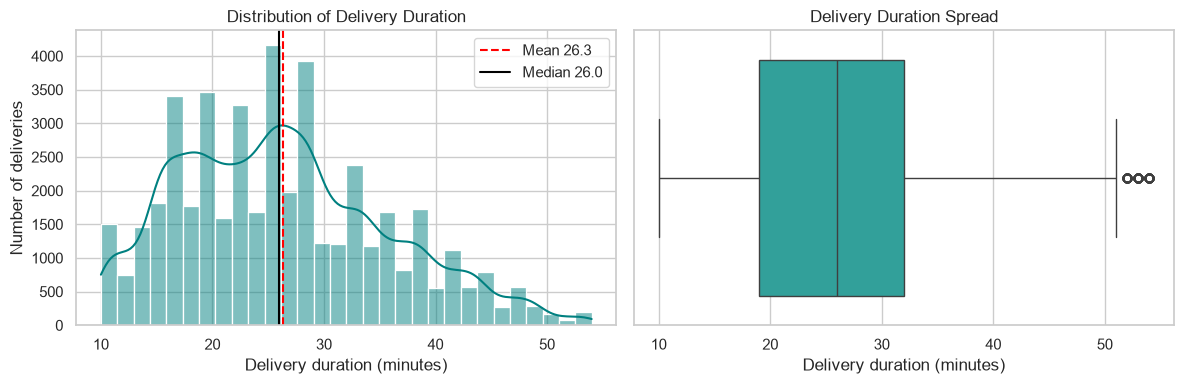

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(d, bins=30, kde=True, color="teal", ax=axes[0])
axes[0].axvline(d.mean(), color="red", linestyle="--", label=f"Mean {d.mean():.1f}")
axes[0].axvline(d.median(), color="black", linestyle="-", label=f"Median {d.median():.1f}")
axes[0].set_title("Distribution of Delivery Duration")
axes[0].set_xlabel("Delivery duration (minutes)")
axes[0].set_ylabel("Number of deliveries")
axes[0].legend()
sns.boxplot(x=d, color="lightseagreen", ax=axes[1])
axes[1].set_title("Delivery Duration Spread")
axes[1].set_xlabel("Delivery duration (minutes)")
plt.tight_layout()
plt.show()

In [8]:
if skew > 0.5:
    shape = "**right-skewed** (a tail of slower deliveries)"
elif skew < -0.5:
    shape = "**left-skewed** (a tail of faster deliveries)"
else:
    shape = "**roughly symmetric**"

show_md(
    f"- **Typical delivery:** the median is **{d.median():.1f} minutes** and the mean is **{d.mean():.1f} minutes**, across **{len(d):,} valid deliveries**.",
    f"- **Spread:** the middle 50% of deliveries took between **{q1:.0f} and {q3:.0f} minutes** (IQR = {iqr:.0f}); the standard deviation is {d.std():.1f} minutes; the range is {d.min()} to {d.max()} minutes.",
    f"- **Shape:** skewness is {skew:.2f}, so the distribution looks {shape}. The mean is {abs(d.mean() - d.median()):.1f} minutes {'above' if d.mean() > d.median() else 'below' if d.mean() < d.median() else 'equal to'} the median.",
    f"- **Extreme values:** {n_extreme:,} deliveries ({n_extreme / len(d) * 100:.1f}%) fall outside 1.5 x IQR. " + ("They are kept, because they may be genuine slow or fast deliveries." if n_extreme else "None need special treatment."),
)

- **Typical delivery:** the median is **26.0 minutes** and the mean is **26.3 minutes**, across **45,584 valid deliveries**.
- **Spread:** the middle 50% of deliveries took between **19 and 32 minutes** (IQR = 13); the standard deviation is 9.4 minutes; the range is 10 to 54 minutes.
- **Shape:** skewness is 0.49, so the distribution looks **roughly symmetric**. The mean is 0.3 minutes above the median.
- **Extreme values:** 270 deliveries (0.6%) fall outside 1.5 x IQR. They are kept, because they may be genuine slow or fast deliveries.

## 4. Comparing Operational Factors

For each categorical factor the tables show the **number of deliveries**, each group's **share** of all deliveries, the **mean** and **median** duration, and the **mean straight-line distance**. Group sizes matter, because a difference between a very large and a very small group is less reliable. The distance column also helps check whether groups differ in something other than the factor being compared (a possible confounder).

In [9]:
MIN_RELIABLE_N = 30   # groups smaller than this are flagged as small

def group_summary(data, col, preferred_order=None):
    # Delivery count, share, mean and median duration (and mean distance) for each category of one column
    sub = data.dropna(subset=[col])
    agg = {"Deliveries": (TARGET, "count"), "Mean duration (min)": (TARGET, "mean"), "Median duration (min)": (TARGET, "median")}
    if "distance_km" in sub.columns:
        agg["Mean distance (km)"] = ("distance_km", "mean")
    g = sub.groupby(col).agg(**agg)
    g.insert(1, "Share of deliveries (%)", g["Deliveries"] / g["Deliveries"].sum() * 100)
    if preferred_order and set(g.index) <= set(preferred_order):
        g = g.reindex([c for c in preferred_order if c in g.index])
    else:
        g = g.sort_values("Median duration (min)", ascending=False)
    return g, len(data) - len(sub)

def show_group_table(g, title, label):
    out = g.copy()
    for c in out.columns:
        out[c] = out[c].round(1) if c != "Deliveries" else out[c].astype(int)
    out = out.reset_index().rename(columns={out.index.name or "index": label})
    show_md(f"**{title}**", "", md_table(out))

def gap_text(g, label):
    # Plain-language description of the highest vs lowest median group
    hi, lo = g["Median duration (min)"].idxmax(), g["Median duration (min)"].idxmin()
    hi_m, lo_m = g.loc[hi, "Median duration (min)"], g.loc[lo, "Median duration (min)"]
    return hi, lo, hi_m, lo_m

### 4.1 Traffic

In [10]:
traffic_summary = None
if HAS["Traffic"]:
    TRAFFIC_ORDER = ["Low", "Medium", "High", "Jam"]
    traffic_summary, traffic_excl = group_summary(df, "Road_traffic_density", TRAFFIC_ORDER)
    show_group_table(traffic_summary, "Delivery duration by traffic category", "Traffic category")
    print(f"Deliveries excluded from this table (traffic value missing): {traffic_excl:,}")
else:
    show_md("The traffic field is not available, so this analysis could not be performed.")

**Delivery duration by traffic category**

| Traffic category | Deliveries | Share of deliveries (%) | Mean duration (min) | Median duration (min) | Mean distance (km) |
| --- | --- | --- | --- | --- | --- |
| Low | 15476 | 34.4 | 21.3 | 20.0 | 8.1 |
| Medium | 10945 | 24.3 | 26.7 | 27.0 | 11.1 |
| High | 4423 | 9.8 | 27.2 | 27.0 | 4.4 |
| Jam | 14139 | 31.4 | 31.2 | 31.0 | 12.0 |

Deliveries excluded from this table (traffic value missing): 601


In [11]:
if traffic_summary is not None:
    hi, lo, hi_m, lo_m = gap_text(traffic_summary, "traffic")
    small = traffic_summary[traffic_summary["Deliveries"] < MIN_RELIABLE_N].index.tolist()
    show_md(
        f"- **Highest median duration:** `{hi}` traffic at **{hi_m:.1f} min** ({int(traffic_summary.loc[hi, 'Deliveries']):,} deliveries).",
        f"- **Lowest median duration:** `{lo}` traffic at **{lo_m:.1f} min** ({int(traffic_summary.loc[lo, 'Deliveries']):,} deliveries).",
        f"- **Gap:** {hi_m - lo_m:.1f} minutes between the highest and lowest median groups.",
        f"- **Group-size check:** " + (f"groups below {MIN_RELIABLE_N} deliveries: {small}." if small else f"all groups have at least {MIN_RELIABLE_N} deliveries."),
    )

- **Highest median duration:** `Jam` traffic at **31.0 min** (14,139 deliveries).
- **Lowest median duration:** `Low` traffic at **20.0 min** (15,476 deliveries).
- **Gap:** 11.0 minutes between the highest and lowest median groups.
- **Group-size check:** all groups have at least 30 deliveries.

### 4.2 Weather

In [12]:
weather_summary = None
if HAS["Weather"]:
    weather_summary, weather_excl = group_summary(df, "Weather_conditions")
    show_group_table(weather_summary, "Delivery duration by weather category", "Weather category")
    print(f"Deliveries excluded from this table (weather value missing): {weather_excl:,}")
else:
    show_md("The weather field is not available, so this analysis could not be performed.")

**Delivery duration by weather category**

| Weather category | Deliveries | Share of deliveries (%) | Mean duration (min) | Median duration (min) | Mean distance (km) |
| --- | --- | --- | --- | --- | --- |
| Cloudy | 7533 | 16.8 | 28.9 | 28.0 | 9.8 |
| Fog | 7653 | 17.0 | 28.9 | 28.0 | 9.8 |
| Sandstorms | 7494 | 16.7 | 25.9 | 26.0 | 9.7 |
| Stormy | 7584 | 16.9 | 25.9 | 26.0 | 9.7 |
| Windy | 7422 | 16.5 | 26.1 | 26.0 | 9.7 |
| Sunny | 7282 | 16.2 | 21.9 | 20.0 | 9.6 |

Deliveries excluded from this table (weather value missing): 616


In [13]:
if weather_summary is not None:
    hi, lo, hi_m, lo_m = gap_text(weather_summary, "weather")
    small = weather_summary[weather_summary["Deliveries"] < MIN_RELIABLE_N].index.tolist()
    show_md(
        f"- **Highest median duration:** `{hi}` at **{hi_m:.1f} min** ({int(weather_summary.loc[hi, 'Deliveries']):,} deliveries).",
        f"- **Lowest median duration:** `{lo}` at **{lo_m:.1f} min** ({int(weather_summary.loc[lo, 'Deliveries']):,} deliveries).",
        f"- **Gap:** {hi_m - lo_m:.1f} minutes between the highest and lowest median groups.",
        f"- **Group-size check:** " + (f"groups below {MIN_RELIABLE_N} deliveries: {small}." if small else f"all groups have at least {MIN_RELIABLE_N} deliveries."),
    )

- **Highest median duration:** `Cloudy` at **28.0 min** (7,533 deliveries).
- **Lowest median duration:** `Sunny` at **20.0 min** (7,282 deliveries).
- **Gap:** 8.0 minutes between the highest and lowest median groups.
- **Group-size check:** all groups have at least 30 deliveries.

### 4.3 Vehicle type

In [14]:
vehicle_summary = None
if HAS["Vehicle type"]:
    vehicle_summary, vehicle_excl = group_summary(df, "Type_of_vehicle")
    show_group_table(vehicle_summary, "Delivery duration by vehicle type", "Vehicle type")
    print(f"Deliveries excluded from this table (vehicle value missing): {vehicle_excl:,}")
else:
    show_md("The vehicle-type field is not available, so this analysis could not be performed.")

**Delivery duration by vehicle type**

| Vehicle type | Deliveries | Share of deliveries (%) | Mean duration (min) | Median duration (min) | Mean distance (km) |
| --- | --- | --- | --- | --- | --- |
| bicycle | 68 | 0.1 | 26.4 | 26.0 | 9.2 |
| motorcycle | 26429 | 58.0 | 27.6 | 26.0 | 9.7 |
| electric_scooter | 3814 | 8.4 | 24.5 | 24.0 | 9.7 |
| scooter | 15273 | 33.5 | 24.5 | 24.0 | 9.8 |

Deliveries excluded from this table (vehicle value missing): 0


In [15]:
if vehicle_summary is not None:
    hi, lo, hi_m, lo_m = gap_text(vehicle_summary, "vehicle")
    small = vehicle_summary[vehicle_summary["Deliveries"] < MIN_RELIABLE_N].index.tolist()
    show_md(
        f"- **Highest median duration:** `{hi}` at **{hi_m:.1f} min** ({int(vehicle_summary.loc[hi, 'Deliveries']):,} deliveries).",
        f"- **Lowest median duration:** `{lo}` at **{lo_m:.1f} min** ({int(vehicle_summary.loc[lo, 'Deliveries']):,} deliveries).",
        f"- **Gap:** {hi_m - lo_m:.1f} minutes between the highest and lowest median groups.",
        f"- **Group-size check:** " + (f"groups below {MIN_RELIABLE_N} deliveries: {small}." if small else f"all groups have at least {MIN_RELIABLE_N} deliveries."),
    )

- **Highest median duration:** `bicycle` at **26.0 min** (68 deliveries).
- **Lowest median duration:** `electric_scooter` at **24.0 min** (3,814 deliveries).
- **Gap:** 2.0 minutes between the highest and lowest median groups.
- **Group-size check:** all groups have at least 30 deliveries.

### 4.4 Quick visual check of the three comparisons (exploratory; the final charts come in Week 3)

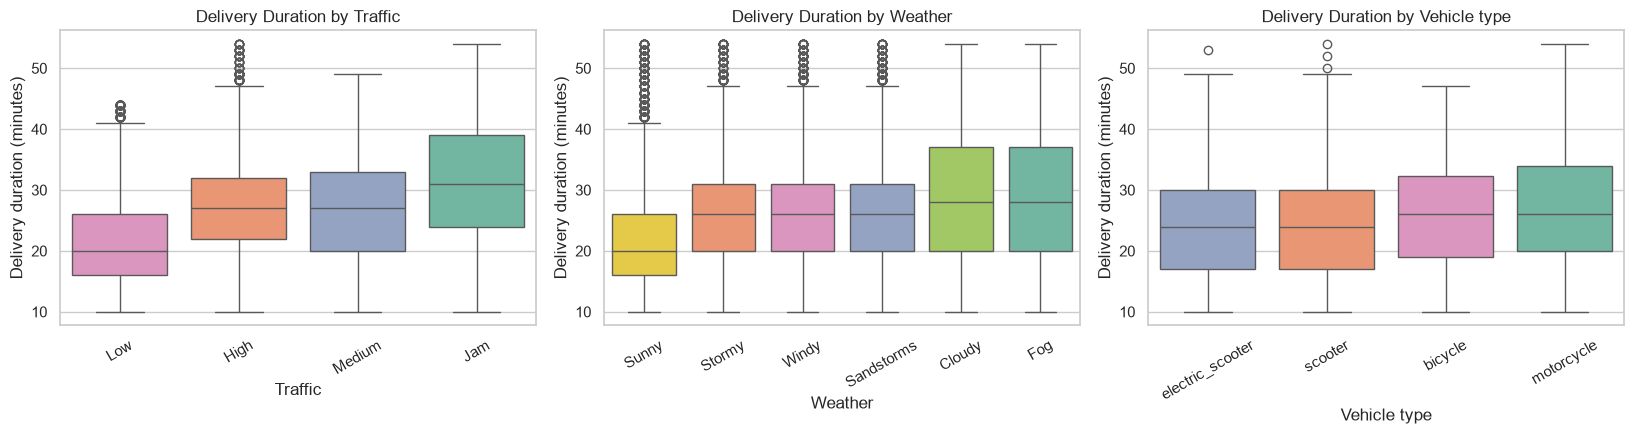

In [16]:
panels = [(c, t) for c, t, ok in [("Road_traffic_density", "Traffic", HAS["Traffic"]),
                                   ("Weather_conditions", "Weather", HAS["Weather"]),
                                   ("Type_of_vehicle", "Vehicle type", HAS["Vehicle type"])] if ok]
if panels:
    fig, axes = plt.subplots(1, len(panels), figsize=(5.5 * len(panels), 4.5), squeeze=False)
    for ax, (col, title) in zip(axes[0], panels):
        order = df.groupby(col)[TARGET].median().sort_values().index
        sns.boxplot(data=df, x=col, y=TARGET, order=order, hue=col, palette="Set2", legend=False, ax=ax)
        ax.set_title(f"Delivery Duration by {title}")
        ax.set_xlabel(title)
        ax.set_ylabel("Delivery duration (minutes)")
        ax.tick_params(axis="x", rotation=30)
    plt.tight_layout()
    plt.show()

## 5. Distance Analysis

**What:** measure how delivery distance relates to delivery duration with a correlation coefficient, and draw the initial scatter plot.
**Why:** distance is the most intuitive factor to test first, and it is also a possible confounder for the other comparisons.
**Method:** Pearson's r measures how close the relationship is to a straight line. Spearman's rho measures whether duration tends to rise with distance in general, and is less affected by extreme values. Both are calculated.

In [17]:
dist_stats = None
if HAS_DISTANCE and df["distance_km"].notna().sum() > 2:
    pair = df[["distance_km", TARGET]].dropna()
    pearson = pair["distance_km"].corr(pair[TARGET], method="pearson")
    spearman = pair["distance_km"].corr(pair[TARGET], method="spearman")
    n_pair = len(pair)
    dist_stats = {"pearson": pearson, "spearman": spearman, "n": n_pair}

    corr_table = pd.DataFrame({
        "Measure": ["Pearson correlation (r)", "Spearman rank correlation (rho)", "r squared", "Deliveries used"],
        "Value": [round(pearson, 3), round(spearman, 3), round(pearson ** 2, 3), f"{n_pair:,}"],
    })
    show_md("**Distance vs. delivery duration**", "", md_table(corr_table))
else:
    show_md("Distance could not be calculated, so this analysis could not be performed.")

**Distance vs. delivery duration**

| Measure | Value |
| --- | --- |
| Pearson correlation (r) | 0.321 |
| Spearman rank correlation (rho) | 0.32 |
| r squared | 0.103 |
| Deliveries used | 41,513 |

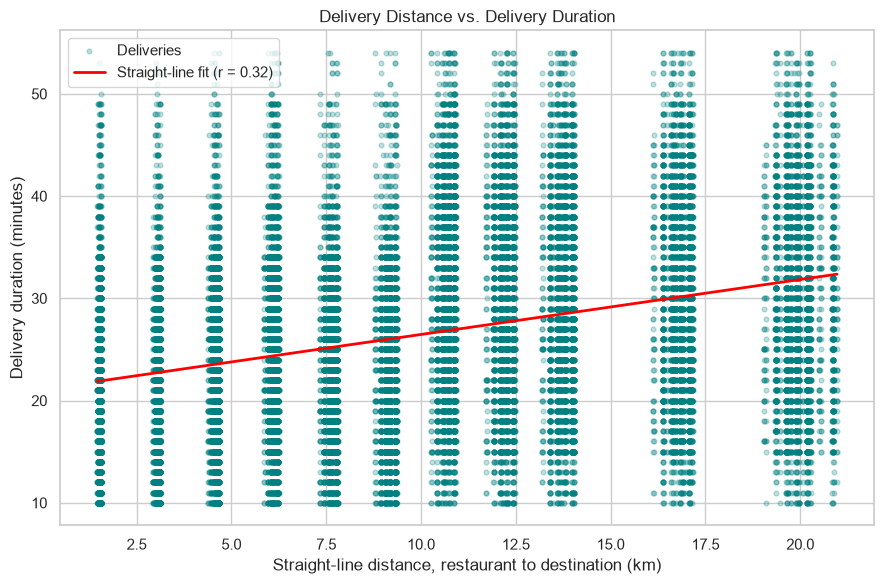

Saved: C:\Users\HP\Documents\food-delivery-data-analysis\visualizations\initial_distance_vs_duration.png


In [18]:
VIS_DIR = os.path.join(PROJECT_ROOT, "visualizations")
os.makedirs(VIS_DIR, exist_ok=True)
SCATTER_PATH = os.path.join(VIS_DIR, "initial_distance_vs_duration.png")

if dist_stats:
    fig, ax = plt.subplots(figsize=(9, 6))
    ax.scatter(pair["distance_km"], pair[TARGET], alpha=0.25, s=12, color="teal", label="Deliveries")
    slope, intercept = np.polyfit(pair["distance_km"], pair[TARGET], 1)
    xs = np.linspace(pair["distance_km"].min(), pair["distance_km"].max(), 100)
    ax.plot(xs, slope * xs + intercept, color="red", linewidth=2, label=f"Straight-line fit (r = {dist_stats['pearson']:.2f})")
    ax.set_title("Delivery Distance vs. Delivery Duration")
    ax.set_xlabel("Straight-line distance, restaurant to destination (km)")
    ax.set_ylabel("Delivery duration (minutes)")
    ax.legend()
    plt.tight_layout()
    fig.savefig(SCATTER_PATH, dpi=150)
    plt.show()
    print("Saved:", SCATTER_PATH)

In [19]:
if dist_stats:
    r = dist_stats["pearson"]
    strength = "negligible" if abs(r) < 0.1 else "weak" if abs(r) < 0.3 else "moderate" if abs(r) < 0.5 else "strong"
    direction = "positive (longer distances go with longer durations)" if r > 0 else "negative (longer distances go with shorter durations)"

    # Duration by distance band (quartiles of distance)
    band = pd.qcut(pair["distance_km"].rank(method="first"), 4, labels=["Q1 shortest", "Q2", "Q3", "Q4 longest"])
    band_table = pair.groupby(band, observed=True).agg(**{
        "Deliveries": (TARGET, "count"),
        "Distance range (km)": ("distance_km", lambda s: f"{s.min():.1f} to {s.max():.1f}"),
        "Mean duration (min)": (TARGET, "mean"),
        "Median duration (min)": (TARGET, "median"),
    })
    band_out = band_table.copy()
    band_out["Mean duration (min)"] = band_out["Mean duration (min)"].round(1)
    band_out["Median duration (min)"] = band_out["Median duration (min)"].round(1)
    band_out = band_out.reset_index().rename(columns={"index": "Distance band", band_table.index.name or "index": "Distance band"})
    show_md("**Delivery duration by distance band (quartiles of distance)**", "", md_table(band_out))

    show_md(
        f"- The Pearson correlation is **{r:.3f}** ({strength}, {direction}); Spearman's rho is {dist_stats['spearman']:.3f}, based on {dist_stats['n']:,} deliveries.",
        f"- Distance linearly accounts for about **{r ** 2 * 100:.1f}%** of the variation in delivery duration (r squared), so **{100 - r ** 2 * 100:.1f}%** is left to other factors or noise.",
        f"- Median duration in the shortest-distance band is **{band_table['Median duration (min)'].iloc[0]:.1f} min** and in the longest-distance band **{band_table['Median duration (min)'].iloc[-1]:.1f} min**.",
        "- Caution: the distance is straight-line, not road distance, and rows with invalid coordinates were excluded.",
    )

**Delivery duration by distance band (quartiles of distance)**

| Distance band | Deliveries | Distance range (km) | Mean duration (min) | Median duration (min) |
| --- | --- | --- | --- | --- |
| Q1 shortest | 10379 | 1.5 to 4.7 | 22.1 | 21.0 |
| Q2 | 10378 | 4.7 to 9.2 | 24.4 | 25.0 |
| Q3 | 10378 | 9.2 to 13.7 | 28.9 | 28.0 |
| Q4 longest | 10378 | 13.7 to 21.0 | 29.9 | 29.0 |

- The Pearson correlation is **0.321** (moderate, positive (longer distances go with longer durations)); Spearman's rho is 0.320, based on 41,513 deliveries.
- Distance linearly accounts for about **10.3%** of the variation in delivery duration (r squared), so **89.7%** is left to other factors or noise.
- Median duration in the shortest-distance band is **21.0 min** and in the longest-distance band **29.0 min**.
- Caution: the distance is straight-line, not road distance, and rows with invalid coordinates were excluded.

## 6. Additional Fields

**What:** check multiple deliveries, ratings and partner age against delivery duration.
**Why:** these fields may relate to duration. **Important:** there is no data dictionary, so their meanings are **inferred from the column names** (for example, `multiple_deliveries` is assumed to be the number of other deliveries carried at the same time). Any result here is only as reliable as that assumption.
**Not performed:** partner experience, because the dataset has no direct experience field.

In [20]:
multi_summary = None
if HAS["Multiple deliveries"]:
    multi_summary, multi_excl = group_summary(df, "multiple_deliveries")
    multi_summary = multi_summary.sort_index()
    show_group_table(multi_summary, "Delivery duration by multiple_deliveries value (meaning inferred from the column name)", "multiple_deliveries")
    print(f"Deliveries excluded (value missing): {multi_excl:,}")
else:
    show_md("The `multiple_deliveries` field is not available, so this analysis could not be performed.")

**Delivery duration by multiple_deliveries value (meaning inferred from the column name)**

| multiple_deliveries | Deliveries | Share of deliveries (%) | Mean duration (min) | Median duration (min) | Mean distance (km) |
| --- | --- | --- | --- | --- | --- |
| 0.0 | 14094.0 | 31.6 | 22.9 | 22.0 | 9.1 |
| 1.0 | 28151.0 | 63.1 | 26.9 | 26.0 | 9.8 |
| 2.0 | 1985.0 | 4.5 | 40.5 | 40.0 | 12.9 |
| 3.0 | 361.0 | 0.8 | 47.8 | 48.0 | 13.0 |

Deliveries excluded (value missing): 993


In [21]:
def quartile_table(series, label):
    # Median duration for the lowest to highest quarter of a numeric field
    pair_x = pd.DataFrame({"x": series, "y": df[TARGET]}).dropna()
    q = pd.qcut(pair_x["x"].rank(method="first"), 4, labels=["Q1 (lowest)", "Q2", "Q3", "Q4 (highest)"])
    t = pair_x.groupby(q, observed=True).agg(**{
        "Deliveries": ("y", "count"),
        f"{label} range": ("x", lambda s: f"{s.min():.1f} to {s.max():.1f}"),
        "Mean duration (min)": ("y", "mean"),
        "Median duration (min)": ("y", "median"),
    })
    rho = pair_x["x"].corr(pair_x["y"], method="spearman")
    return t, rho, len(pair_x)

rating_tbl = rating_rho = rating_n = None
if HAS["Ratings"]:
    rating_tbl, rating_rho, rating_n = quartile_table(df["Delivery_person_Ratings"], "Rating")
    out = rating_tbl.copy()
    out["Mean duration (min)"] = out["Mean duration (min)"].round(1)
    out["Median duration (min)"] = out["Median duration (min)"].round(1)
    show_md("**Delivery duration by rating quartile (rating meaning and scale inferred)**", "", md_table(out.reset_index().rename(columns={out.index.name or 'index': 'Rating group'})))
    show_md(f"Spearman correlation between rating and duration: **{rating_rho:.3f}** (n = {rating_n:,}).")
else:
    show_md("The ratings field is not available, so this analysis could not be performed.")

**Delivery duration by rating quartile (rating meaning and scale inferred)**

| Rating group | Deliveries | Rating range | Mean duration (min) | Median duration (min) |
| --- | --- | --- | --- | --- |
| Q1 (lowest) | 10906 | 1.0 to 4.5 | 32.1 | 33.0 |
| Q2 | 10906 | 4.5 to 4.7 | 24.4 | 24.0 |
| Q3 | 10905 | 4.7 to 4.9 | 24.1 | 23.0 |
| Q4 (highest) | 10906 | 4.9 to 5.0 | 24.6 | 24.0 |

Spearman correlation between rating and duration: **-0.294** (n = 43,623).

In [22]:
age_tbl = age_rho = age_n = None
if HAS["Partner age"]:
    age_tbl, age_rho, age_n = quartile_table(df["Delivery_person_Age"].astype("float64"), "Age")
    out = age_tbl.copy()
    out["Mean duration (min)"] = out["Mean duration (min)"].round(1)
    out["Median duration (min)"] = out["Median duration (min)"].round(1)
    show_md("**Delivery duration by partner-age quartile**", "", md_table(out.reset_index().rename(columns={out.index.name or 'index': 'Age group'})))
    show_md(f"Spearman correlation between partner age and duration: **{age_rho:.3f}** (n = {age_n:,}). Age is **not** a measure of experience.")
else:
    show_md("The partner-age field is not available, so this analysis could not be performed.")

**Delivery duration by partner-age quartile**

| Age group | Deliveries | Age range | Mean duration (min) | Median duration (min) |
| --- | --- | --- | --- | --- |
| Q1 (lowest) | 10933 | 15.0 to 25.0 | 23.0 | 22.0 |
| Q2 | 10932 | 25.0 to 30.0 | 23.1 | 22.0 |
| Q3 | 10932 | 30.0 to 35.0 | 29.6 | 29.0 |
| Q4 (highest) | 10933 | 35.0 to 50.0 | 29.5 | 29.0 |

Spearman correlation between partner age and duration: **0.312** (n = 43,730). Age is **not** a measure of experience.

## 7. Key Observations

Each observation lists the **question**, **metric**, **actual result**, **comparison** and **group size**, followed by **what the data shows** and a cautious **interpretation**. The numbers are filled in by code from the tables above, so they always match the calculations.

Interpretation is separated from the data on purpose. A difference between groups is an **association**, not proof of a cause. Other factors that differ between groups (distance, city, time of day, order type) may be partly responsible.

In [23]:
observations = []

def add_obs(question, metric, result, comparison, group_size, shows, interpretation):
    observations.append(dict(question=question, metric=metric, result=result, comparison=comparison,
                             group_size=group_size, shows=shows, interpretation=interpretation))

def group_obs(summary, factor_label, question, extra_note):
    # Build an observation from a group-summary table
    hi, lo, hi_m, lo_m = gap_text(summary, factor_label)
    n_hi, n_lo = int(summary.loc[hi, "Deliveries"]), int(summary.loc[lo, "Deliveries"])
    smallest = int(summary["Deliveries"].min())
    conf = ""
    if "Mean distance (km)" in summary.columns:
        conf = (f" The groups also differ in average distance: {summary.loc[hi, 'Mean distance (km)']:.1f} km for `{hi}` "
                f"versus {summary.loc[lo, 'Mean distance (km)']:.1f} km for `{lo}`.")
    add_obs(
        question, "Median delivery duration (minutes)",
        f"`{hi}`: {hi_m:.1f} min; `{lo}`: {lo_m:.1f} min",
        f"Gap of {hi_m - lo_m:.1f} min ({hi_m / lo_m:.2f}x)" if lo_m else f"Gap of {hi_m - lo_m:.1f} min",
        f"`{hi}` n = {n_hi:,}; `{lo}` n = {n_lo:,}; smallest group n = {smallest:,}" + (" (small, treat with caution)" if smallest < MIN_RELIABLE_N else ""),
        f"Median duration differs by {hi_m - lo_m:.1f} minutes between the slowest and fastest {factor_label} groups.{conf}",
        (extra_note if (lo_m and hi_m / lo_m >= 1.10) else f"The difference between the highest and lowest groups is small ({hi_m - lo_m:.1f} min, {hi_m / lo_m:.2f}x), so there is little evidence in this data that {factor_label} is associated with delivery duration. Other factors may matter more.") if lo_m else extra_note,
    )

# 1. Baseline
add_obs(
    "What does a typical delivery look like, and is the duration evenly spread?",
    "Mean, median and standard deviation of delivery duration (minutes)",
    f"Median {d.median():.1f} min; mean {d.mean():.1f} min; standard deviation {d.std():.1f} min",
    f"Mean is {abs(d.mean() - d.median()):.1f} min {'above' if d.mean() > d.median() else 'below'} the median; skewness {skew:.2f}",
    f"n = {len(d):,} valid deliveries",
    f"Half of all deliveries took between {q1:.0f} and {q3:.0f} minutes, and {n_extreme:,} ({n_extreme / len(d) * 100:.1f}%) fall outside 1.5 x IQR.",
    "The median is a sound summary of a typical delivery. A gap between mean and median suggests a few unusually slow or fast deliveries influence the average, so medians are reported alongside means throughout.",
)

# 2-3. Traffic and weather
if traffic_summary is not None:
    group_obs(traffic_summary, "traffic", "Does delivery duration differ across traffic categories?",
              "Duration is associated with traffic category. Congestion may be one reason, but the groups may also differ in distance, city or time of day, so this does not prove that traffic caused the difference.")
if weather_summary is not None:
    group_obs(weather_summary, "weather", "Does delivery duration differ across weather conditions?",
              "Duration is associated with weather. Conditions may affect riding speed, but weather may also coincide with particular cities, seasons or times of day, so no causal claim is made.")

# 4. Distance
if dist_stats:
    first_med, last_med = band_table["Median duration (min)"].iloc[0], band_table["Median duration (min)"].iloc[-1]
    add_obs(
        "Is a longer delivery distance associated with a longer delivery duration?",
        "Pearson correlation (r) and Spearman rho between straight-line distance and duration",
        f"r = {dist_stats['pearson']:.3f}; rho = {dist_stats['spearman']:.3f} ({strength})",
        f"Median duration {first_med:.1f} min in the shortest-distance quarter vs {last_med:.1f} min in the longest",
        f"n = {dist_stats['n']:,} deliveries with valid coordinates",
        f"The relationship is {strength} and {'positive' if dist_stats['pearson'] > 0 else 'negative'}; distance linearly accounts for about {dist_stats['pearson'] ** 2 * 100:.1f}% of the variation in duration.",
        "Distance is related to duration to the degree shown, and most of the variation is left to other factors. Straight-line distance understates real road distance, and traffic and vehicle type may blur the relationship.",
    )

# 5. Vehicle
if vehicle_summary is not None:
    group_obs(vehicle_summary, "vehicle type", "Does delivery duration differ across vehicle types?",
              "Duration is associated with vehicle type. Vehicle types may be used on different kinds of routes or in different cities, so a difference does not show that the vehicle itself changes delivery time.")

# 6. Multiple deliveries
if multi_summary is not None and len(multi_summary) > 1:
    first_k, last_k = multi_summary.index[0], multi_summary.index[-1]
    add_obs(
        "Is duration different when more deliveries are carried at once (meaning inferred from the column name)?",
        "Median delivery duration (minutes) by multiple_deliveries value",
        f"Value {first_k}: {multi_summary.loc[first_k, 'Median duration (min)']:.1f} min; value {last_k}: {multi_summary.loc[last_k, 'Median duration (min)']:.1f} min",
        f"Gap of {multi_summary.loc[last_k, 'Median duration (min)'] - multi_summary.loc[first_k, 'Median duration (min)']:.1f} min between the lowest and highest values",
        f"Value {first_k} n = {int(multi_summary.loc[first_k, 'Deliveries']):,}; value {last_k} n = {int(multi_summary.loc[last_k, 'Deliveries']):,}; smallest group n = {int(multi_summary['Deliveries'].min()):,}",
        f"Median duration ranges from {multi_summary['Median duration (min)'].min():.1f} to {multi_summary['Median duration (min)'].max():.1f} minutes across the values of this field (see the table above).",
        ("If the field means what its name suggests, carrying several orders at once may affect time per order. The meaning is not documented, so this is a hypothesis to confirm, not a finding."
         if multi_summary['Median duration (min)'].max() - multi_summary['Median duration (min)'].min() >= 2
         else "The medians barely differ across values, so this field shows little association with duration here. Its meaning is also undocumented."),
    )

# 7. Ratings
if rating_tbl is not None:
    add_obs(
        "Are higher-rated delivery partners associated with different delivery durations (rating meaning inferred)?",
        "Spearman correlation between rating and duration; median duration in the lowest vs highest rating quarter",
        f"rho = {rating_rho:.3f}",
        f"Median {rating_tbl['Median duration (min)'].iloc[0]:.1f} min (lowest-rated quarter) vs {rating_tbl['Median duration (min)'].iloc[-1]:.1f} min (highest-rated quarter)",
        f"n = {rating_n:,} deliveries with a rating",
        "The correlation is " + ("negligible" if abs(rating_rho) < 0.1 else "weak" if abs(rating_rho) < 0.3 else "moderate or stronger") + ".",
        "Ratings may reflect customer experience, which could depend on delivery speed in either direction. The scale and rating method are undocumented, so the direction of any link cannot be interpreted.",
    )

# 8. Age
if age_tbl is not None:
    add_obs(
        "Is delivery-partner age associated with delivery duration?",
        "Spearman correlation between age and duration; median duration in the youngest vs oldest quarter",
        f"rho = {age_rho:.3f}",
        f"Median {age_tbl['Median duration (min)'].iloc[0]:.1f} min (youngest quarter) vs {age_tbl['Median duration (min)'].iloc[-1]:.1f} min (oldest quarter)",
        f"n = {age_n:,} deliveries with a recorded age",
        "The correlation is " + ("negligible" if abs(age_rho) < 0.1 else "weak" if abs(age_rho) < 0.3 else "moderate or stronger") + ".",
        "Age is not a measure of experience, so this says nothing direct about how experience affects delivery time.",
    )

lines = [f"**{len(observations)} observations from the analysis above**", ""]
for i, o in enumerate(observations, 1):
    lines += [
        f"### Observation {i}",
        f"- **Question:** {o['question']}",
        f"- **Metric:** {o['metric']}",
        f"- **Result:** {o['result']}",
        f"- **Comparison:** {o['comparison']}",
        f"- **Group size:** {o['group_size']}",
        f"- **What the data shows:** {o['shows']}",
        f"- **Interpretation (not proven by the data):** {o['interpretation']}",
        "",
    ]
show_md(*lines)

**8 observations from the analysis above**

### Observation 1
- **Question:** What does a typical delivery look like, and is the duration evenly spread?
- **Metric:** Mean, median and standard deviation of delivery duration (minutes)
- **Result:** Median 26.0 min; mean 26.3 min; standard deviation 9.4 min
- **Comparison:** Mean is 0.3 min above the median; skewness 0.49
- **Group size:** n = 45,584 valid deliveries
- **What the data shows:** Half of all deliveries took between 19 and 32 minutes, and 270 (0.6%) fall outside 1.5 x IQR.
- **Interpretation (not proven by the data):** The median is a sound summary of a typical delivery. A gap between mean and median suggests a few unusually slow or fast deliveries influence the average, so medians are reported alongside means throughout.

### Observation 2
- **Question:** Does delivery duration differ across traffic categories?
- **Metric:** Median delivery duration (minutes)
- **Result:** `Jam`: 31.0 min; `Low`: 20.0 min
- **Comparison:** Gap of 11.0 min (1.55x)
- **Group size:** `Jam` n = 14,139; `Low` n = 15,476; smallest group n = 4,423
- **What the data shows:** Median duration differs by 11.0 minutes between the slowest and fastest traffic groups. The groups also differ in average distance: 12.0 km for `Jam` versus 8.1 km for `Low`.
- **Interpretation (not proven by the data):** Duration is associated with traffic category. Congestion may be one reason, but the groups may also differ in distance, city or time of day, so this does not prove that traffic caused the difference.

### Observation 3
- **Question:** Does delivery duration differ across weather conditions?
- **Metric:** Median delivery duration (minutes)
- **Result:** `Cloudy`: 28.0 min; `Sunny`: 20.0 min
- **Comparison:** Gap of 8.0 min (1.40x)
- **Group size:** `Cloudy` n = 7,533; `Sunny` n = 7,282; smallest group n = 7,282
- **What the data shows:** Median duration differs by 8.0 minutes between the slowest and fastest weather groups. The groups also differ in average distance: 9.8 km for `Cloudy` versus 9.6 km for `Sunny`.
- **Interpretation (not proven by the data):** Duration is associated with weather. Conditions may affect riding speed, but weather may also coincide with particular cities, seasons or times of day, so no causal claim is made.

### Observation 4
- **Question:** Is a longer delivery distance associated with a longer delivery duration?
- **Metric:** Pearson correlation (r) and Spearman rho between straight-line distance and duration
- **Result:** r = 0.321; rho = 0.320 (moderate)
- **Comparison:** Median duration 21.0 min in the shortest-distance quarter vs 29.0 min in the longest
- **Group size:** n = 41,513 deliveries with valid coordinates
- **What the data shows:** The relationship is moderate and positive; distance linearly accounts for about 10.3% of the variation in duration.
- **Interpretation (not proven by the data):** Distance is related to duration to the degree shown, and most of the variation is left to other factors. Straight-line distance understates real road distance, and traffic and vehicle type may blur the relationship.

### Observation 5
- **Question:** Does delivery duration differ across vehicle types?
- **Metric:** Median delivery duration (minutes)
- **Result:** `bicycle`: 26.0 min; `electric_scooter`: 24.0 min
- **Comparison:** Gap of 2.0 min (1.08x)
- **Group size:** `bicycle` n = 68; `electric_scooter` n = 3,814; smallest group n = 68
- **What the data shows:** Median duration differs by 2.0 minutes between the slowest and fastest vehicle type groups. The groups also differ in average distance: 9.2 km for `bicycle` versus 9.7 km for `electric_scooter`.
- **Interpretation (not proven by the data):** The difference between the highest and lowest groups is small (2.0 min, 1.08x), so there is little evidence in this data that vehicle type is associated with delivery duration. Other factors may matter more.

### Observation 6
- **Question:** Is duration different when more deliveries are carried at once (meaning inferred from the column name)?
- **Metric:** Median delivery duration (minutes) by multiple_deliveries value
- **Result:** Value 0.0: 22.0 min; value 3.0: 48.0 min
- **Comparison:** Gap of 26.0 min between the lowest and highest values
- **Group size:** Value 0.0 n = 14,094; value 3.0 n = 361; smallest group n = 361
- **What the data shows:** Median duration ranges from 22.0 to 48.0 minutes across the values of this field (see the table above).
- **Interpretation (not proven by the data):** If the field means what its name suggests, carrying several orders at once may affect time per order. The meaning is not documented, so this is a hypothesis to confirm, not a finding.

### Observation 7
- **Question:** Are higher-rated delivery partners associated with different delivery durations (rating meaning inferred)?
- **Metric:** Spearman correlation between rating and duration; median duration in the lowest vs highest rating quarter
- **Result:** rho = -0.294
- **Comparison:** Median 33.0 min (lowest-rated quarter) vs 24.0 min (highest-rated quarter)
- **Group size:** n = 43,623 deliveries with a rating
- **What the data shows:** The correlation is weak.
- **Interpretation (not proven by the data):** Ratings may reflect customer experience, which could depend on delivery speed in either direction. The scale and rating method are undocumented, so the direction of any link cannot be interpreted.

### Observation 8
- **Question:** Is delivery-partner age associated with delivery duration?
- **Metric:** Spearman correlation between age and duration; median duration in the youngest vs oldest quarter
- **Result:** rho = 0.312
- **Comparison:** Median 22.0 min (youngest quarter) vs 29.0 min (oldest quarter)
- **Group size:** n = 43,730 deliveries with a recorded age
- **What the data shows:** The correlation is moderate or stronger.
- **Interpretation (not proven by the data):** Age is not a measure of experience, so this says nothing direct about how experience affects delivery time.


## 8. Limitations and Notes

- **Association, not causation.** None of the comparisons control for other factors. For example, traffic, weather, vehicle type and city may overlap, so a difference attributed to one factor may partly belong to another.
- **Distance is straight-line**, not road distance, and it is only available for rows with valid coordinates (invalid ones were flagged in Week 1).
- **No data dictionary.** The meanings of `multiple_deliveries`, ratings and the vehicle-condition field are inferred from column names. Results using them are tentative.
- **Partner experience could not be analysed**, because the dataset has no direct experience field. Age is not a substitute.
- **Missing values** (kept as missing in Week 1) are excluded from each comparison only, and the number excluded is printed under each table.
- **Group sizes differ.** Small groups give less reliable averages, so group sizes are reported next to every comparison.
- **Medians are reported next to means** because a few very slow or fast deliveries can pull the mean.
- The final five visualisations and the operational recommendations belong to Weeks 3 and 4.

In [24]:
# Final check that the required Week 2 output exists
print("Scatter plot saved:", os.path.exists(SCATTER_PATH), "->", SCATTER_PATH)
print("Observations written:", len(observations))
assert len(observations) >= 5, "Fewer than five observations were generated; check which fields are available"

Scatter plot saved: True -> C:\Users\HP\Documents\food-delivery-data-analysis\visualizations\initial_distance_vs_duration.png
Observations written: 8


## My Written Observations

### Observation 1: Overall delivery performance
- **Question:** What does a typical delivery look like, and how much does it vary?
- **Metric:** Median, mean and standard deviation of delivery duration (minutes)
- **Result:** Median 26.0 min, mean 26.29 min, standard deviation 9.38 min
- **Comparison:** The middle 50% of deliveries took 19 to 32 minutes (IQR = 13). The range is 10 to 54 minutes.
- **Group size:** n = 45,584 deliveries
- **What the data shows:** The mean and median are almost the same, and skewness is 0.49, so the distribution is close to symmetric with only a slight tail of slower deliveries. Only 270 deliveries (0.6%) fall outside 1.5 x IQR.
- **Interpretation:** A typical delivery takes about 26 minutes, with a fairly wide spread. Extreme values are rare and do not distort the average, so they were kept. The median and mean tell the same story here.

### Observation 2: Traffic and delivery duration
- **Question:** Does delivery duration differ across traffic categories?
- **Metric:** Median delivery duration (minutes)
- **Result:** Low: 20 min; Medium: 27 min; High: 27 min; Jam: 31 min
- **Comparison:** Jam deliveries have a median 11 minutes higher than Low-traffic deliveries (1.55 times as long).
- **Group size:** Low n = 15,476; Jam n = 14,139; Medium n = 10,945; High n = 4,423 (601 deliveries with missing traffic were excluded).
- **What the data shows:** Median duration rises from Low to Jam, and every group has thousands of deliveries.
- **Interpretation:** Heavier traffic is associated with longer deliveries, which is consistent with congestion slowing riders down. However, the groups also differ in distance (see Observation 5), so this does not prove that traffic alone caused the gap.

### Observation 3: Weather and delivery duration
- **Question:** Does delivery duration differ across weather conditions?
- **Metric:** Median delivery duration (minutes)
- **Result:** Sunny: 20 min; Sandstorms, Stormy and Windy: 26 min; Cloudy and Fog: 28 min
- **Comparison:** Cloudy and Fog deliveries have a median 8 minutes higher than Sunny deliveries (1.4 times as long).
- **Group size:** Each category has 7,282 to 7,653 deliveries (about 16 to 17% each); 616 deliveries with missing weather were excluded.
- **What the data shows:** Sunny deliveries are clearly the fastest. Mean distance is almost identical across weather groups (9.6 to 9.8 km), so distance does not explain the gap.
- **Interpretation:** Weather other than Sunny is associated with slower deliveries, which is plausible if conditions reduce visibility or riding speed. It is surprising that Stormy, Windy and Sandstorms (26 min) are faster than Cloudy and Fog (28 min), and this data cannot explain that. Pairs of categories also have identical mean durations (Cloudy and Fog both 28.9; Sandstorms and Stormy both 25.9), which is worth noting as an unusual pattern in the data.

### Observation 4: Vehicle type and delivery duration
- **Question:** Does delivery duration differ across vehicle types?
- **Metric:** Median delivery duration (minutes)
- **Result:** Motorcycle: 26 min; Scooter: 24 min; Electric scooter: 24 min; Bicycle: 26 min
- **Comparison:** Motorcycle deliveries have a median 2 minutes higher than scooter deliveries (mean 27.6 vs 24.5 min, a 3.1 minute gap).
- **Group size:** Motorcycle n = 26,429 (58.0%); Scooter n = 15,273 (33.5%); Electric scooter n = 3,814 (8.4%); Bicycle n = 68 (0.1%).
- **What the data shows:** The differences between vehicle types are small compared with traffic and weather. Average distance is similar across vehicle types (9.2 to 9.8 km).
- **Interpretation:** Vehicle type has a modest association with duration. Motorcycles may be used on different routes or in different cities, so this does not show that the vehicle itself changes delivery time. The bicycle group (68 deliveries) is too small to compare reliably.

### Observation 5: Is the traffic effect just a distance effect?
- **Question:** Do traffic categories differ in delivery distance, and does that explain the duration gap?
- **Metric:** Mean straight-line distance (km) by traffic category
- **Result:** Jam: 12.0 km; Medium: 11.1 km; Low: 8.1 km; High: 4.4 km
- **Comparison:** Jam deliveries travel on average 3.9 km farther than Low-traffic deliveries. High-traffic deliveries have the shortest average distance (4.4 km) yet a median of 27 min, 7 minutes above Low traffic (8.1 km, 20 min).
- **Group size:** Low n = 15,476; Jam n = 14,139; Medium n = 10,945; High n = 4,423.
- **What the data shows:** Distance differs between traffic groups, so it is a confounder for the Jam vs. Low comparison. High traffic breaks the pattern: its deliveries are the shortest but not the fastest.
- **Interpretation:** Part of the Low-to-Jam gap may come from longer distances. The High-traffic result suggests that traffic is associated with longer durations beyond distance alone, but this simple comparison cannot separate the two effects. Comparing traffic groups within similar distance bands would test this properly.
### Observation 6: Distance and delivery duration
- **Question:** Is a longer delivery distance associated with a longer delivery duration?
- **Metric:** Pearson correlation (r), Spearman rank correlation (rho) and median duration by distance band
- **Result:** r = 0.321, rho = 0.320, r squared = 0.103
- **Comparison:** Median duration rises from 21 min in the shortest-distance quarter (1.5 to 4.7 km) to 25, 28 and 29 min in the longer quarters (13.7 to 21.0 km). The longest quarter is 8 minutes (1.38 times) slower than the shortest.
- **Group size:** n = 41,513 deliveries with valid coordinates (4,071, or 8.9%, excluded); about 10,378 per distance band.
- **What the data shows:** The relationship is moderate and positive. Distance linearly accounts for about 10.3% of the variation in delivery duration, so about 89.7% is left to other factors. The increase is steady across the first three bands and nearly flat between the last two (28 to 29 min).
- **Interpretation:** Longer routes tend to take longer, but distance is far from the whole story. Traffic, weather and multiple deliveries all show comparable or larger gaps. Straight-line distance understates real road distance, which may weaken the measured relationship.

### Observation 7: Multiple deliveries and delivery duration
- **Question:** Is duration different when a partner carries more deliveries at once? (Meaning inferred from the column name; there is no data dictionary.)
- **Metric:** Median delivery duration (minutes) by `multiple_deliveries` value
- **Result:** 0: 22 min; 1: 26 min; 2: 40 min; 3: 48 min
- **Comparison:** Deliveries with value 3 have a median 26 minutes higher than value 0 (2.2 times as long). This is the largest gap of any factor examined, compared with 11 min for traffic and 8 min for weather.
- **Group size:** Value 0 n = 14,094 (31.6%); value 1 n = 28,151 (63.1%); value 2 n = 1,985 (4.5%); value 3 n = 361 (0.8%). 993 deliveries with a missing value were excluded.
- **What the data shows:** Duration rises at every step. Mean distance also rises with the value (9.1, 9.8, 12.9 and 13.0 km), so part of the gap may come from longer routes.
- **Interpretation:** If this field is the number of other orders carried at the same time, extra pickups and drop-offs could add time, which fits the pattern. The groups with values 2 and 3 are small (together about 5% of deliveries), and the field's meaning is not documented, so this is a hypothesis to confirm, not a finding.

### Observation 8: Ratings and delivery duration
- **Question:** Are delivery partners with different ratings associated with different delivery durations? (Rating scale and meaning inferred.)
- **Metric:** Spearman correlation between rating and duration, and median duration by rating quarter
- **Result:** rho = -0.294
- **Comparison:** The lowest-rated quarter (ratings 1.0 to 4.5) has a median of 33 min, against 24, 23 and 24 min for the three higher quarters, a gap of 9 to 10 minutes.
- **Group size:** n = 43,623 deliveries with a rating (1,961 excluded); about 10,906 per quarter.
- **What the data shows:** The correlation is weak and negative, but the table shows it is driven by the lowest-rated group. The top three quarters are nearly identical, so there is no steady trend across the rating range.
- **Interpretation:** Deliveries by partners with the lowest ratings are slower, but the direction cannot be determined. Slow deliveries may lead customers to give lower ratings, or lower-rated partners may be slower for other reasons. The rating scale is undocumented, so this is an association only.

### Observation 9: Partner age and delivery duration
- **Question:** Is delivery-partner age associated with delivery duration?
- **Metric:** Spearman correlation between age and duration, and median duration by age quarter
- **Result:** rho = 0.312
- **Comparison:** Median duration is 22 min for ages 15 to 30 and 29 min for ages 30 to 50, a gap of 7 minutes (1.32 times).
- **Group size:** n = 43,730 deliveries with a recorded age (1,854 excluded); about 10,933 per quarter.
- **What the data shows:** The correlation is moderate and positive, but the pattern is a step, not a gradual rise. The two younger quarters (22 min) and two older quarters (29 min) each match each other closely.
- **Interpretation:** Older partners are associated with longer deliveries, but age is not a measure of experience, so this says nothing direct about experience. The step pattern suggests age groups may differ in something else, such as city, vehicle type or order type, which should be checked in later analysis before drawing any conclusion.